In [3]:
from langchain_community.document_loaders import PyPDFLoader
from dotenv import load_dotenv
from langchain_text_splitters import RecursiveCharacterTextSplitter
from langchain_google_genai import GoogleGenerativeAIEmbeddings
from langgraph.graph import StateGraph,START,END
from langchain_openai import ChatOpenAI
import os 
from pydantic import BaseModel,Field
from langchain_core.documents import Document
from typing import List

load_dotenv()



True

In [4]:
model = ChatOpenAI(
    model="meta/muse-glimmer-30b",
    base_url="https://integrate.api.nvidia.com/v1",
    api_key=os.getenv("NVIDIA_API_KEY"),
    temperature=0.2,
    max_tokens=500,
    reasoning_effort="low"
)


embeddings = GoogleGenerativeAIEmbeddings(model="gemini-embedding-001")


In [5]:
from langchain_chroma import Chroma


loader = PyPDFLoader("./data/data_science_syllabus.pdf")

documents = loader.load()

text_splitter = RecursiveCharacterTextSplitter(chunk_size=1000, chunk_overlap=200, separators=[",", "\n\n"])
texts = text_splitter.split_documents(documents)
vector_store: Chroma = Chroma.from_documents(
    documents=documents,
    embedding=embeddings,
    persist_directory="./document_db"
    )

In [6]:
class RagState(BaseModel):
    question: str = Field(description="user question")
    documents: List[Document] = Field(description="documents related to user question",default=[])
    context: str = Field(description="context data for user question",default="")
    answer: str = Field(description="answer to user question",default="")

In [7]:
def retriever_node (state:RagState)->RagState:
    docs= vector_store.similarity_search(state.question,k=4)
    state.documents=docs
    return state

def context_node (state:RagState)->RagState:
    state.context = "\\n\\n".join(d.page_content for d in state.documents)
    return state

def answer_node (state:RagState)->RagState:
    
    prompt = f"""Your are a helpful assistant. Answer the following question based on the context provided,if there 
    is no answer in the context,
    answer with 'I don't know'.\\n\\nContext:\\n{state.context}\\n\\nQuestion:\\n{state.question}"""
       
    res = model.invoke(prompt)
    state.answer = res.content
    return state
    

In [8]:


graph= StateGraph(RagState)


graph.add_node("retriever_node",retriever_node)
graph.add_node("context_node",context_node)
graph.add_node("answer_node",answer_node)

graph.add_edge(START,"retriever_node")
graph.add_edge("retriever_node","context_node")
graph.add_edge("context_node","answer_node")
graph.add_edge("answer_node",END)
graph= graph.compile()

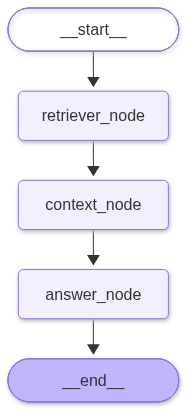

In [9]:
from IPython.display import Image

Image(graph.get_graph().draw_mermaid_png())


In [11]:
res = graph.invoke({
    "question": "whats module 7 is about? "})

In [ ]:
from pprint import pprint


pprint(res["answer"])

('Based on the context provided:\n'
 '\n'
 '**Module 7: Machine Learning – II (Unsupervised & Feature Engineering)**\n'
 '* Duration: Month 7\n'
 '* Length: 3 weeks\n'
 '\n'
 '**Topics:**\n'
 '* KMeans Clustering\n'
 '* Dimensionality Reduction: PCA\n'
 '* Feature selection, encoding, scaling\n'
 '* Model tuning `GridSearchCV`\n'
 '\n'
 '**Tools:**\n'
 '* Scikit-learn, Seaborn, Colab\n'
 '\n'
 '**Mock Interview:** Unsupervised Learning \ue09d Features\n'
 '\n'
 'The context lists a Mini Project for this module as:\n'
 '* Analyze NYC Taxi Dataset using PySpark\n'
 '\n'
 '*Note: The context also shows a “Mini Project: Customer Segmentation / '
 'E-commerce Product Clustering” and a Mock Interview for Unsupervised '
 'Learning under Module 8, so the project association in the provided text is '
 'mixed.*')
